# Radar Echo from an Extended Rigid Target


``` {important} ## Learning Objectives
:class: dropdown
- Understand coherent summation of scatterers within extended target
- Relate target size to wavelength
- Study aspect-dependent RCS
- Investigate frequency scaling
- Analyze angular correlation and RCS statistics
- Explore maneuvering-target signatures
```

## Theory
Coherent monostatic backscatter from multiple point scatterers.

For scatterers located at positions $r_n=(x_n,y_n)$ with amplitudes $a_n$, the monostatic backscattered field is

$$
E(\phi)=\sum_{n=1}^{N} a_n e^{j2k\hat u(\phi)\cdot r_n}
$$

where $k=\frac{2\pi}{\lambda}$ and $\hat u=[\cos\phi,\sin\phi].$

The relative radar cross section (RCS) is $\sigma(\phi)=|E(\phi)|^2.$

This notebook focuses on coherent interference effects and does not model shadowing, polarization, diffraction, multiple scattering, or absolute calibration.


In [23]:
import numpy as np
import matplotlib.pyplot as plt
c=3.e8

Start with generation of the target's mode - a set of scatterers that are located in 2D space and have some scattering characteristics. In reality every scatterer characterised with a complex scattering coefficient $\dot A$, which is defining the amplitude and phase of scatered fild $ {\dot {\vec E^s}}(t,\theta)$:

$$ {\dot {\vec E^s}}(t,\theta) = {\dot A}(\theta) \dot {\vec E^i}(t,\theta) $$

As we consider the case of monostatic radar, when the propagation directions of incident and scattered waves are the same, this coefficient ${\dot A}(\theta)$ is a function on azimuth angle $\theta$ of the line-of-sight directions. For simplicity, in this analysis we neglect this angular dependency, use only real values of $\dot A$.

In [24]:
# change this to False to have a case with one dominant scatterer
is_all_scatterers_equal=False 

def generate_aircraft_scatterers():
    pts=[]
    x=np.linspace(-4,4,12)
    for xi in x: pts.append((xi,0))
    for t in np.linspace(0,1,8):
        pts.append((-0.5+2.5*t,0.2+2.2*t))
        pts.append((-0.5+2.5*t,-(0.2+2.2*t)))
        pts.append((2.0-2.8*t,2.4-1.4*t))
        pts.append((2.0-2.8*t,-(2.4-1.4*t)))
    for t in np.linspace(-1.1,1.1,5): pts.append((-3,t))
    pts.append((4.5,0))
    P=np.unique(np.round(np.array(pts),3),axis=0)
    a=np.ones(len(P))
    if (not is_all_scatterers_equal):
        # edit this set of scatterers to have different amplitudes
        a[P[:,0]>4]=10
    return P,a

scatterers, amplitudes = generate_aircraft_scatterers()
print(f'The number of scatterers: {len(scatterers)}')

The number of scatterers: 48


## Plot the scatterers geometry

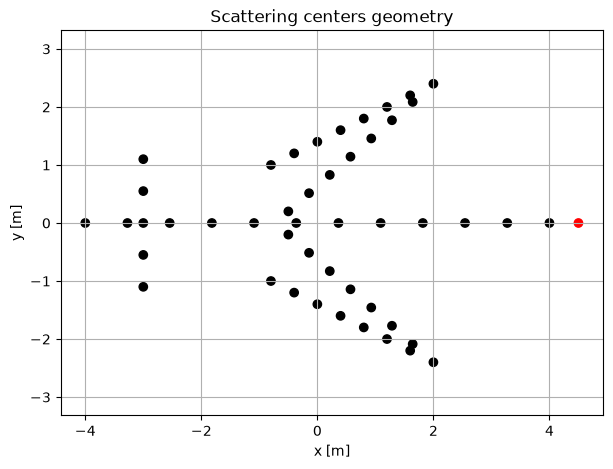

In [25]:
plt.figure(figsize=(7,5))
#plt.scatter(scatterers[:,0],scatterers[:,1],c=amplitudes)
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('black_red', ['black', 'red'])
plt.scatter(scatterers[:,0],scatterers[:,1],c=amplitudes,cmap=cmap)
plt.axis('equal'); plt.grid(); plt.title('Scattering centers geometry'); 
plt.xlabel('x [m]'); plt.ylabel('y [m]');
plt.show()

## Calculate the angular dependency of the backscattering RCS 

In [26]:
def rcs_pattern(scatterers, amplitudes, wavelength, angles):
    k=2*np.pi/wavelength
    ux=np.cos(angles); uy=np.sin(angles)
    E=np.zeros_like(angles,dtype=complex)
    for a,(x,y) in zip(amplitudes,scatterers):
        E += a*np.exp(1j*2*k*(x*ux+y*uy))
    return np.abs(E)**2

frequencies=[100e6,1e9,10e9]
wavelengths=[c/f for f in frequencies]
angles=np.linspace(0,2*np.pi,5000,endpoint=False)

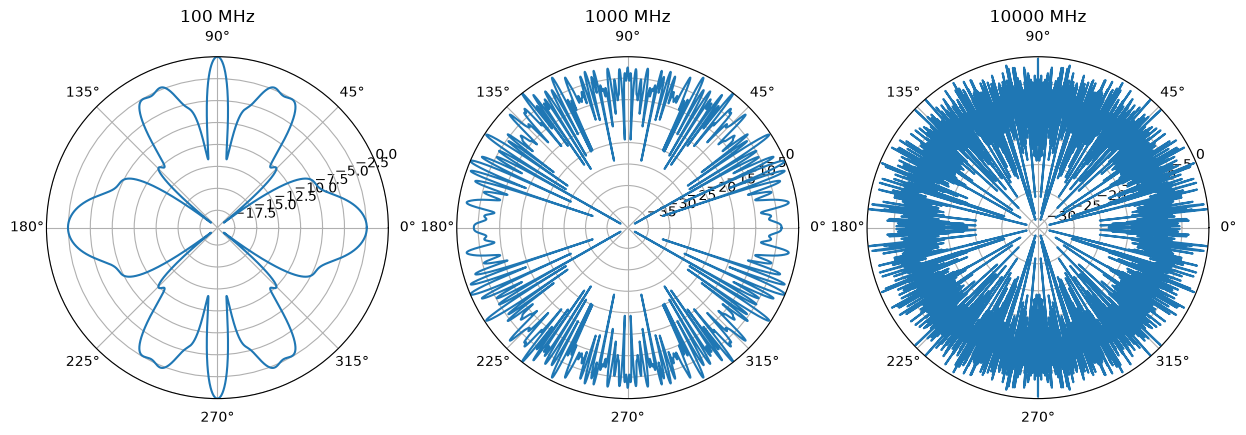

In [27]:
fig,ax=plt.subplots(1,3,subplot_kw={"projection":"polar"},figsize=(15,5))
for aa,f,l in zip(ax,frequencies,wavelengths):
 s=rcs_pattern(scatterers,amplitudes,l,angles)
 aa.plot(angles,10*np.log10(s/s.max()+1e-12)); aa.set_title(f"{f/1e6:.0f} MHz")
plt.show()

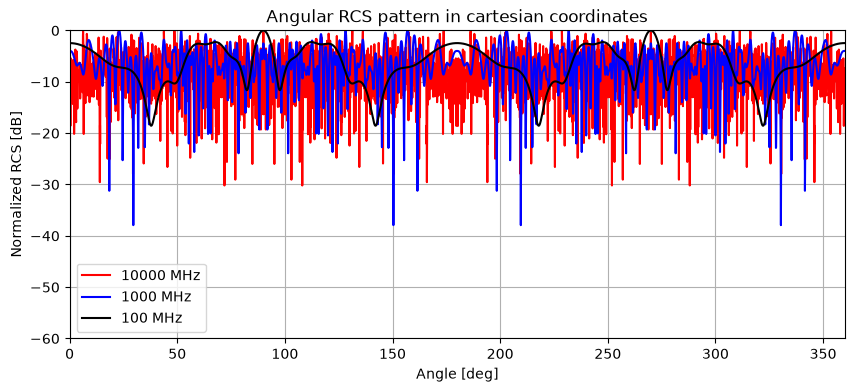

In [28]:
plt.figure(figsize=(10,4))
colors=['r','b','k']
for f,l,cstr in zip(reversed(frequencies),reversed(wavelengths),colors):
    s=rcs_pattern(scatterers,amplitudes,l,angles)
    plt.plot(np.rad2deg(angles),10*np.log10(s/s.max()+1e-12),
             cstr,label=f"{f/1e6:.0f} MHz")
plt.xlabel('Angle [deg]'); plt.ylabel('Normalized RCS [dB]'); 
plt.title('Angular RCS pattern in cartesian coordinates'); 
plt.xlim(0,360); plt.ylim(-60,0)   
plt.legend(); plt.grid(); 
plt.show()

### Statistical distribution of the RCS

m1=10.30, std1=12.07


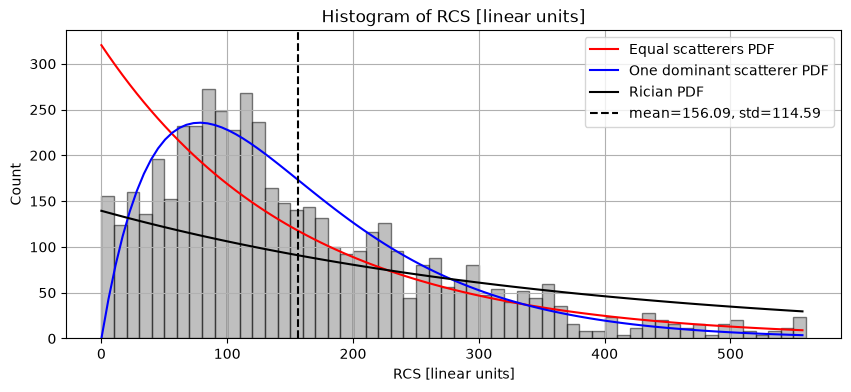

In [29]:
from statistics import mean
import numpy as np
from scipy.special import i0

def rician_power_pdf(P, P0, sigma_s):
    '''
    Rician power PDF.
    
    Parameters
    ----------
    P : float or ndarray
        Random power variable (P >= 0).
    P0 : float
        Deterministic/specular power component.
    sigma_s : float
        Standard deviation of the Gaussian scattering component.

    Returns
    -------
    pdf : float or ndarray
        Probability density W_s(P).
    '''
    P = np.asarray(P, dtype=float)
    pdf = np.zeros_like(P)
    mask = P >= 0
    pdf[mask] = (
        1.0 / (2.0 * sigma_s**2)
        * np.exp(-(P[mask] + P0) / (2.0 * sigma_s**2))
        * i0(np.sqrt(P0 * P[mask]) / sigma_s**2)
    )
    return pdf

s=rcs_pattern(scatterers,amplitudes,wavelengths[1],angles)

plt.figure(figsize=(10,4))
binwidth = 10
bins=range(0, int(max(s)) + binwidth, binwidth)
plt.hist(s, bins, density=False, alpha=0.5, 
         color='grey', edgecolor='black')
plt.title("Histogram of RCS [linear units]"); 
plt.xlabel("RCS [linear units]"); plt.ylabel("Count")     
ms=mean(s); std=np.std(s)
x = np.linspace(0, max(s), 100)
pdf = binwidth*len(s)*(1.0 / ms) * np.exp(-x/ms)  
plt.plot(x, pdf, 'r-', label='Equal scatterers PDF')
if (not is_all_scatterers_equal):
    pdf1=binwidth*len(s)*(4.0*x/ms**2) * np.exp(-2*x/ms)
    plt.plot(x, pdf1, 'b-', label='One dominant scatterer PDF')
    m1=np.sqrt(np.sqrt(ms**2-std**2)); std1=np.sqrt(ms-m1);
    print(f"m1={m1:.2f}, std1={std1:.2f}")
    pdf2=binwidth*len(s)*rician_power_pdf(x, m1+50, std1)
    plt.plot(x, pdf2, 'k-', label='Rician PDF')
plt.axvline(ms,color='k',linestyle='--',
            label=f"mean={ms:.2f}, std={std:.2f}"); 
plt.legend(); 
plt.grid()

plt.show()

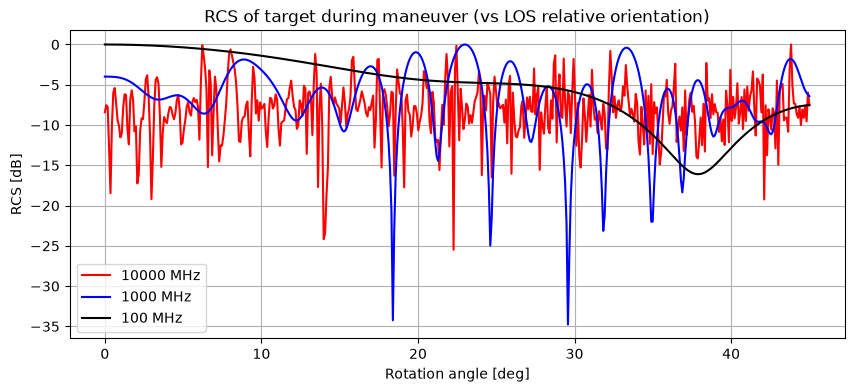

In [30]:
def rotate_target(p,t):
 R=np.array([[np.cos(t),-np.sin(t)],[np.sin(t),np.cos(t)]])
 return p@R.T

rots=np.deg2rad(np.linspace(0,45,500))

plt.figure(figsize=(10,4))
for f,l,cstr in zip(reversed(frequencies),reversed(wavelengths),colors):
 y=[]
 for r in rots:
  y.append(rcs_pattern(rotate_target(scatterers,r),amplitudes,l,np.array([0]))[0])
 y=np.array(y)
 plt.plot(np.rad2deg(rots),10*np.log10(y/y.max()+1e-12),cstr,label=f"{f/1e6:.0f} MHz")
plt.title("RCS of target during maneuver (vs LOS relative orientation)"); 
plt.xlabel("Rotation angle [deg]"); 
plt.ylabel("RCS [dB]");
plt.legend(); plt.grid(); plt.show()

## Angular Correlation Functions at Different Frequencies

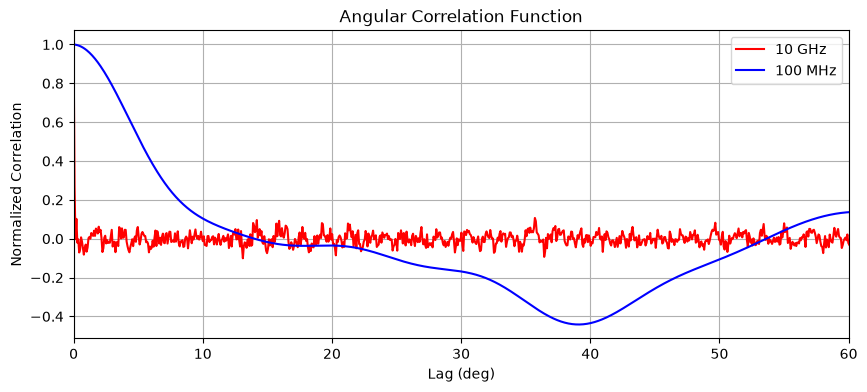

In [31]:
s1=rcs_pattern(scatterers,amplitudes,c/10e9,angles)
s2=rcs_pattern(scatterers,amplitudes,c/100e6,angles)

s1=s1-s1.mean()
s2=s2-s2.mean() 
ac1=np.correlate(s1,s1,mode='full')[len(s)-1:]  
ac1=ac1/ac1[0]
ac2=np.correlate(s2,s2,mode='full')[len(s)-1:]
ac2=ac2/ac2[0]
lag1=np.arange(len(ac1))*np.rad2deg(angles[1]-angles[0])
lag2=np.arange(len(ac2))*np.rad2deg(angles[1]-angles[0])     

plt.figure(figsize=(10,4))
plt.plot(lag1,ac1,'r-',label="10 GHz"); 
plt.plot(lag2,ac2,'b-',label="100 MHz")
plt.xlim(0,60); plt.grid()
plt.title('Angular Correlation Function')
plt.xlabel('Lag (deg)')
plt.ylabel('Normalized Correlation')
plt.legend();
plt.show()

The RCS angular dependency at higher frequency shows very narrow correlation interval, every new radar pulse response is completely independent from the previous one even for slow maneuvering target. At low frequency the situation is quite different - within quite reasonable interval of observation angles the target's RCS can be assumed quite constant.

### Nice image of the RCS angular dependency in a wide frequency interval

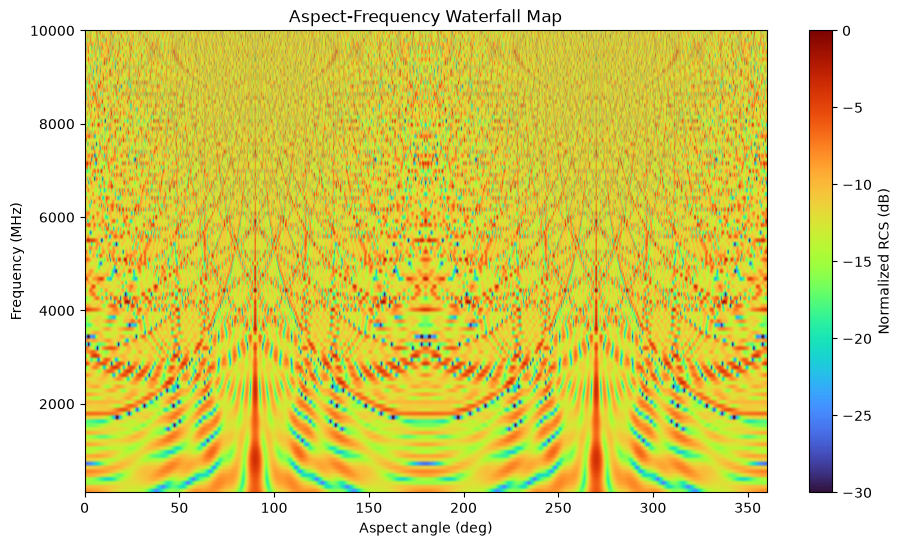

In [32]:
freqs=np.logspace(8,10,120)
R=np.zeros((len(freqs),len(angles)))
for i,f in enumerate(freqs):
    R[i]=rcs_pattern(scatterers,amplitudes,c/f,angles)
plt.figure(figsize=(11,6))
plt.imshow(10*np.log10(R/R.max()+1e-12),aspect='auto',origin='lower',
           extent=[0,360,100,10000],cmap='turbo',vmin=-30.,vmax=0)
plt.colorbar(label='Normalized RCS (dB)')
plt.xlabel('Aspect angle (deg)'); plt.ylabel('Frequency (MHz)')
plt.title('Aspect-Frequency Waterfall Map')
plt.show()

See, how the frequency scaling influence the RCS angular dependency...

## Exercise Questions

### Exercise 1

Investigate the effect of target size on radar cross-section (RCS) angular behavior.

**Question**:
 If all dimensions of a target are doubled while keeping the radar frequency constant, how would you expect the angular correlation width and the rate of RCS fluctuations with aspect angle to change? Explain your reasoning.

### Exercise 2

Study the influence of geometric perturbations on coherent scattering.

**Question**:
 Assume that each scatterer position is randomly perturbed by ±5 cm. Compare the expected impact of these perturbations on the RCS pattern at frequencies of 100 MHz, 1 GHz, and 10 GHz.

### Exercise 3

Examine the role of nonuniform scatterer amplitudes.

**Question**:
 How does assigning random amplitudes to individual scattering centres affect the overall RCS distribution compared with using identical amplitudes for all scatterers?

### Exercise 4

Estimate angular decorrelation behavior at different radar frequencies.

**Question**:
 For the same target geometry, rank the angular decorrelation widths at 100 MHz, 1 GHz, and 10 GHz. Explain the physical reason for the trend.

### Exercise 5

Compare RCS signatures of different target shapes.

**Question**:
 Simulate or sketch the expected angular RCS patterns for:

a) A circular target
 b) A triangular target
 c) A random cloud of scatterers

Describe the main characteristics of each pattern.

### Exercise 6

Analyze electrical size scaling.

**Question**:
 What happens to the target electrical size D/λD/\lambda when all target dimensions are doubled? How does this change affect the angular RCS response and correlation width?

### Exercise 7

Relate geometric perturbations to wavelength.

**Question**:
 A scatterer position error of ±5 cm is introduced. Express this perturbation as a fraction of the wavelength at:

- 100 MHz
- 1 GHz
- 10 GHz

Based on these values, discuss how sensitivity to perturbations changes with frequency.

### Exercise 8

Explore amplitude statistics in distributed targets.

**Question**:
 How do random variations in scatterer amplitudes influence the RCS histogram and the contribution of individual scatterers to the coherent sum?

### Exercise 9

Measure angular decorrelation width.

**Question**:
 Estimate and compare the angular decorrelation widths for a given target observed at:

- 100 MHz
- 1 GHz
- 10 GHz

What trend do you observe, and why?

### Exercise 10

Shape recognition from RCS behavior.

**Question**:
 Compare the angular RCS signatures of:

- Circular targets
- Triangular targets
- Random scatterer clouds

What characteristic features could be used to distinguish these target types?

## Discussion Question

What radar scattering phenomena are captured by this simplified coherent-scatterer model? Which important physical effects are neglected, and how might these omissions limit the realism of the simulation?
